# Model Comparison and Error Analysis — Review 1

This notebook consolidates the **Naive 168-hour baseline + Model 1 + Model 2 + Model 3** results and performs the final Review 1 comparison/error analysis.

### What this notebook does
1. Loads the saved metrics and prediction files.
2. Builds one comparison table for all four approaches.
3. Calculates improvement percentages over the naive baseline and over Linear Regression where useful.
4. Compares train vs test performance for the three ML models.
5. Analyzes prediction error by hour.
6. Analyzes prediction error by pickup zone.
7. Identifies where the best model (**HistGradientBoosting**) performs poorly.
8. Produces presentation-ready plots.

**Important:** All official model comparison metrics remain based on the same chronological test period.


## 1. Imports and configuration


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Libraries imported successfully.


## 2. Locate repository and load saved modelling outputs


In [3]:
def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in [start, *start.parents]:
        if (path / "models" / "modeling" / "train.csv").exists():
            return path
    raise FileNotFoundError(
        "Could not find the project repository. Run the modelling notebooks first."
    )

REPO_ROOT = find_repo_root()
MODELING_DIR = REPO_ROOT / "models" / "modeling"

print("Repository:", REPO_ROOT)
print("Modeling directory:", MODELING_DIR)

required_files = [
    "train.csv",
    "test.csv",
    "baseline_metrics.csv",
    "baseline_168h_predictions.csv",
    "model_1_metrics.csv",
    "model_1_predictions.csv",
    "model_2_metrics.csv",
    "model_2_predictions.csv",
    "model_3_metrics.csv",
    "model_3_predictions.csv",
]

missing_files = [f for f in required_files if not (MODELING_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(f"Missing modelling outputs: {missing_files}")

print("All required modelling files found.")


Repository: /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting
Modeling directory: /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling
All required modelling files found.


## 3. Load metrics and predictions


In [4]:
train_df = pd.read_csv(MODELING_DIR / "train.csv", parse_dates=["pickup_hour"])
test_df = pd.read_csv(MODELING_DIR / "test.csv", parse_dates=["pickup_hour"])

baseline_metrics = pd.read_csv(MODELING_DIR / "baseline_metrics.csv")
model_1_metrics = pd.read_csv(MODELING_DIR / "model_1_metrics.csv")
model_2_metrics = pd.read_csv(MODELING_DIR / "model_2_metrics.csv")
model_3_metrics = pd.read_csv(MODELING_DIR / "model_3_metrics.csv")

baseline_pred = pd.read_csv(
    MODELING_DIR / "baseline_168h_predictions.csv",
    parse_dates=["pickup_hour"]
)
model_1_pred = pd.read_csv(
    MODELING_DIR / "model_1_predictions.csv",
    parse_dates=["pickup_hour"]
)
model_2_pred = pd.read_csv(
    MODELING_DIR / "model_2_predictions.csv",
    parse_dates=["pickup_hour"]
)
model_3_pred = pd.read_csv(
    MODELING_DIR / "model_3_predictions.csv",
    parse_dates=["pickup_hour"]
)

print("Train:", train_df.shape)
print("Test :", test_df.shape)
print("Baseline predictions:", baseline_pred.shape)
print("Model 1 predictions:", model_1_pred.shape)
print("Model 2 predictions:", model_2_pred.shape)
print("Model 3 predictions:", model_3_pred.shape)


Train: (460920, 17)
Test : (115368, 17)
Baseline predictions: (115368, 6)
Model 1 predictions: (115368, 7)
Model 2 predictions: (115368, 6)
Model 3 predictions: (115368, 6)


## 4. Final comparison table


In [5]:
def get_test_row(metrics_df):
    rows = metrics_df[metrics_df["dataset"].eq("test")]
    if rows.empty:
        raise ValueError("No test row found.")
    return rows.iloc[0]

baseline = baseline_metrics.iloc[0]
m1 = get_test_row(model_1_metrics)
m2 = get_test_row(model_2_metrics)
m3 = get_test_row(model_3_metrics)

comparison = pd.DataFrame([
    {
        "model": "Naive 168-hour baseline",
        "MAE": baseline["MAE"],
        "RMSE": baseline["RMSE"],
        "R2": baseline["R2"],
    },
    {
        "model": "Model 1 - Linear Regression",
        "MAE": m1["MAE"],
        "RMSE": m1["RMSE"],
        "R2": m1["R2"],
    },
    {
        "model": "Model 2 - Random Forest",
        "MAE": m2["MAE"],
        "RMSE": m2["RMSE"],
        "R2": m2["R2"],
    },
    {
        "model": "Model 3 - HistGradientBoosting",
        "MAE": m3["MAE"],
        "RMSE": m3["RMSE"],
        "R2": m3["R2"],
    },
])

display(comparison.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "R2": "{:.4f}",
}))


,model,MAE,RMSE,R2
0,Naive 168-hour baseline,9.3074,24.0566,0.8776
1,Model 1 - Linear Regression,7.4861,15.7036,0.9478
2,Model 2 - Random Forest,6.7993,15.2593,0.9507
3,Model 3 - HistGradientBoosting,5.7841,13.1632,0.9633


## 5. Improvement over the naive baseline


In [6]:
baseline_mae = comparison.loc[0, "MAE"]
baseline_rmse = comparison.loc[0, "RMSE"]
baseline_r2 = comparison.loc[0, "R2"]

improvement = comparison.copy()
improvement["MAE_improvement_vs_baseline_pct"] = (
    (baseline_mae - improvement["MAE"]) / baseline_mae * 100
)
improvement["RMSE_improvement_vs_baseline_pct"] = (
    (baseline_rmse - improvement["RMSE"]) / baseline_rmse * 100
)
improvement["R2_gain_vs_baseline"] = improvement["R2"] - baseline_r2

display(improvement.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "R2": "{:.4f}",
    "MAE_improvement_vs_baseline_pct": "{:.2f}%",
    "RMSE_improvement_vs_baseline_pct": "{:.2f}%",
    "R2_gain_vs_baseline": "{:.4f}",
}))


,model,MAE,RMSE,R2,MAE_improvement_vs_baseline_pct,RMSE_improvement_vs_baseline_pct,R2_gain_vs_baseline
0,Naive 168-hour baseline,9.3074,24.0566,0.8776,0.00%,0.00%,0.0000
1,Model 1 - Linear Regression,7.4861,15.7036,0.9478,19.57%,34.72%,0.0703
2,Model 2 - Random Forest,6.7993,15.2593,0.9507,26.95%,36.57%,0.0732
3,Model 3 - HistGradientBoosting,5.7841,13.1632,0.9633,37.85%,45.28%,0.0858


## 6. ML model train-vs-test comparison


In [7]:
ml_metrics = pd.concat([
    model_1_metrics.assign(model="Model 1 - Linear Regression"),
    model_2_metrics.assign(model="Model 2 - Random Forest"),
    model_3_metrics.assign(model="Model 3 - HistGradientBoosting"),
], ignore_index=True)

train_test_wide = ml_metrics.pivot(
    index="model",
    columns="dataset",
    values=["MAE", "RMSE", "R2"]
)

train_test_wide.columns = [
    f"{metric}_{dataset}"
    for metric, dataset in train_test_wide.columns
]
train_test_wide = train_test_wide.reset_index()

train_test_wide["MAE_gap_test_minus_train"] = (
    train_test_wide["MAE_test"] - train_test_wide["MAE_train"]
)
train_test_wide["RMSE_gap_test_minus_train"] = (
    train_test_wide["RMSE_test"] - train_test_wide["RMSE_train"]
)
train_test_wide["R2_drop_train_to_test"] = (
    train_test_wide["R2_train"] - train_test_wide["R2_test"]
)

display(train_test_wide.style.format({
    "MAE_train": "{:.4f}",
    "MAE_test": "{:.4f}",
    "RMSE_train": "{:.4f}",
    "RMSE_test": "{:.4f}",
    "R2_train": "{:.4f}",
    "R2_test": "{:.4f}",
    "MAE_gap_test_minus_train": "{:.4f}",
    "RMSE_gap_test_minus_train": "{:.4f}",
    "R2_drop_train_to_test": "{:.4f}",
}))


,model,MAE_test,MAE_train,RMSE_test,RMSE_train,R2_test,R2_train,MAE_gap_test_minus_train,RMSE_gap_test_minus_train,R2_drop_train_to_test
0,Model 1 - Linear Regression,7.4861,7.3050,15.7036,16.4003,0.9478,0.9553,0.1811,-0.6967,0.0075
1,Model 2 - Random Forest,6.7993,6.1986,15.2593,13.6979,0.9507,0.9688,0.6007,1.5614,0.0181
2,Model 3 - HistGradientBoosting,5.7841,5.5382,13.1632,12.8706,0.9633,0.9725,0.2460,0.2925,0.0092


## 7. Identify the best model


In [8]:
best_model_row = comparison.loc[comparison["MAE"].idxmin()]
BEST_MODEL_NAME = best_model_row["model"]

print("Best model by test MAE:", BEST_MODEL_NAME)
print(f"Test MAE : {best_model_row['MAE']:.4f}")
print(f"Test RMSE: {best_model_row['RMSE']:.4f}")
print(f"Test R²  : {best_model_row['R2']:.4f}")


Best model by test MAE: Model 3 - HistGradientBoosting
Test MAE : 5.7841
Test RMSE: 13.1632
Test R²  : 0.9633


## 8. Prepare error data for all models


In [9]:
base = test_df[["PULocationID", "pickup_hour", "trip_count"]].copy()
base["hour"] = base["pickup_hour"].dt.hour
base["day_of_week"] = base["pickup_hour"].dt.dayofweek
base["month"] = base["pickup_hour"].dt.month
base["is_weekend"] = base["day_of_week"].isin([5, 6])

error_data = base.copy()

prediction_frames = [
    ("Naive 168h baseline", "naive_168h_baseline", baseline_pred["baseline_prediction"].to_numpy()),
    ("Model 1 - Linear Regression", "model_1_linear_regression", model_1_pred["prediction"].to_numpy()),
    ("Model 2 - Random Forest", "model_2_random_forest", model_2_pred["prediction"].to_numpy()),
    ("Model 3 - HistGradientBoosting", "model_3_histgradientboosting", model_3_pred["prediction"].to_numpy()),
]

if any(len(pred) != len(error_data) for _, _, pred in prediction_frames):
    raise ValueError("Prediction row counts do not match the test dataset.")

for display_name, prefix, pred in prediction_frames:
    error_data[f"{prefix}_prediction"] = pred
    error_data[f"{prefix}_abs_error"] = (
        error_data["trip_count"] - pred
    ).abs()


display(error_data.head())


,PULocationID,pickup_hour,trip_count,hour,day_of_week,month,is_weekend,naive_168h_baseline_prediction,naive_168h_baseline_abs_error,model_1_linear_regression_prediction,model_1_linear_regression_abs_error,model_2_random_forest_prediction,model_2_random_forest_abs_error,model_3_histgradientboosting_prediction,model_3_histgradientboosting_abs_error
0,2,2026-01-25 04:00:00,0,4,6,1,True,0,0,0.000000,0.000000,0.662211,0.662211,0.009341,0.009341
1,4,2026-01-25 04:00:00,14,4,6,1,True,36,22,29.791329,15.791329,37.244330,23.244330,30.828360,16.828360
2,7,2026-01-25 04:00:00,0,4,6,1,True,20,20,11.209729,11.209729,13.699783,13.699783,15.329374,15.329374
3,8,2026-01-25 04:00:00,0,4,6,1,True,0,0,0.000000,0.000000,0.610659,0.610659,0.066803,0.066803
4,9,2026-01-25 04:00:00,0,4,6,1,True,0,0,0.000000,0.000000,0.728326,0.728326,0.111493,0.111493


## 9. Error by hour — all models


,hour,actual_mean,baseline_mae,model_1_mae,model_2_mae,model_3_mae
0,0,23.429028,7.477621,6.618967,7.387381,4.890142
1,1,15.413257,4.974211,4.770959,5.638004,3.191696
2,2,10.358269,3.348252,3.451158,3.851327,2.315988
3,3,7.245951,2.685635,3.038672,2.968359,1.931661
4,4,5.827122,2.803520,3.073571,2.701370,2.103617
5,5,6.593375,2.832712,3.419837,2.849502,2.345670
6,6,13.307660,4.414907,5.311202,4.085865,3.586048
7,7,23.934990,7.748240,9.225290,6.577066,5.523140
8,8,31.528157,9.411387,7.145277,6.515205,5.975911
9,9,32.663975,9.013665,6.624995,5.795632,5.985357


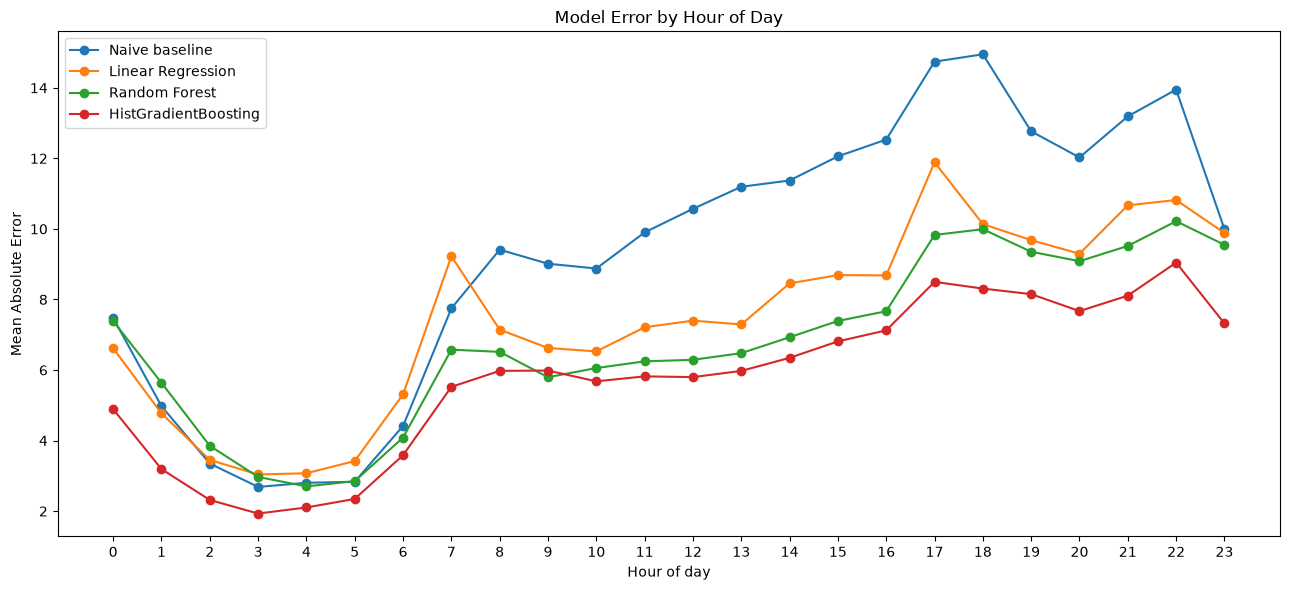

In [10]:
hour_error = (
    error_data.groupby("hour")
    .agg(
        actual_mean=("trip_count", "mean"),
        baseline_mae=("naive_168h_baseline_abs_error", "mean"),
        model_1_mae=("model_1_linear_regression_abs_error", "mean"),
        model_2_mae=("model_2_random_forest_abs_error", "mean"),
        model_3_mae=("model_3_histgradientboosting_abs_error", "mean"),
    )
    .reset_index()
)

display(hour_error)

plt.figure(figsize=(13, 6))
plt.plot(hour_error["hour"], hour_error["baseline_mae"], marker="o", label="Naive baseline")
plt.plot(hour_error["hour"], hour_error["model_1_mae"], marker="o", label="Linear Regression")
plt.plot(hour_error["hour"], hour_error["model_2_mae"], marker="o", label="Random Forest")
plt.plot(hour_error["hour"], hour_error["model_3_mae"], marker="o", label="HistGradientBoosting")
plt.xlabel("Hour of day")
plt.ylabel("Mean Absolute Error")
plt.title("Model Error by Hour of Day")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()


## 10. Best-model error by hour


,hour,MAE,actual_mean,prediction_mean,absolute_bias
0,0,4.890142,23.429028,24.122094,0.693065
1,1,3.191696,15.413257,15.922774,0.509517
2,2,2.315988,10.358269,10.456395,0.098125
3,3,1.931661,7.245951,7.139606,-0.106345
4,4,2.103617,5.827122,5.880794,0.053672
5,5,2.345670,6.593375,6.425279,-0.168096
6,6,3.586048,13.307660,13.189777,-0.117883
7,7,5.523140,23.934990,24.616338,0.681349
8,8,5.975911,31.528157,32.362593,0.834436
9,9,5.985357,32.663975,34.420319,1.756344


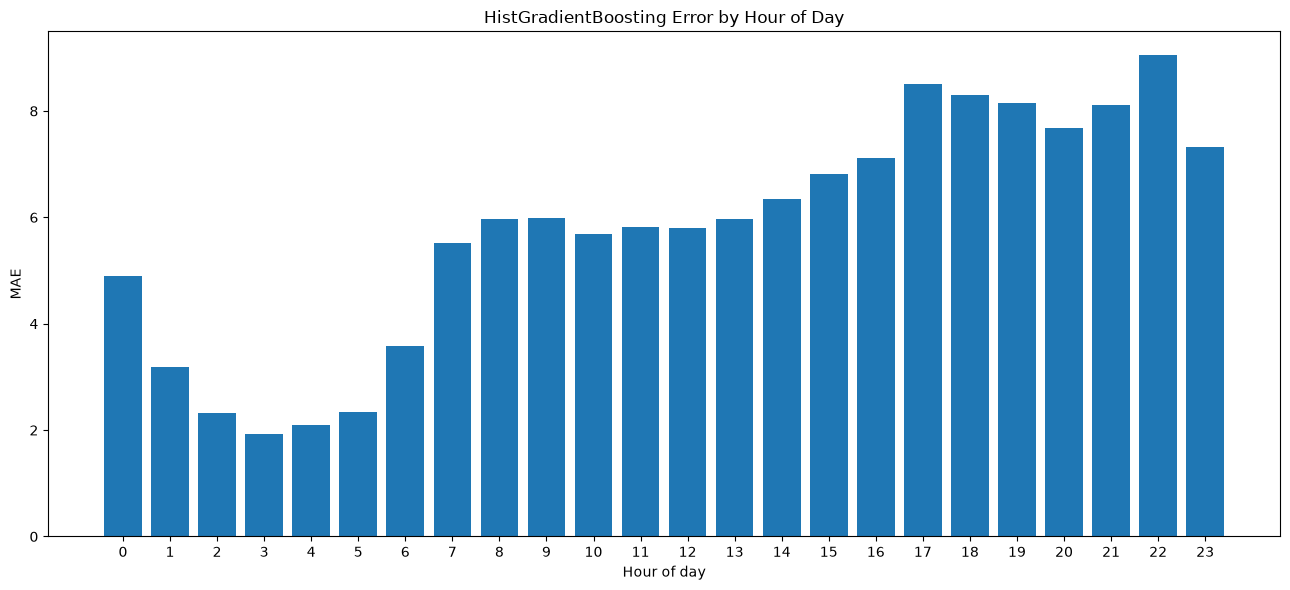

In [11]:
best_error_col = "model_3_histgradientboosting_abs_error"

best_by_hour = (
    error_data.groupby("hour")
    .agg(
        MAE=(best_error_col, "mean"),
        actual_mean=("trip_count", "mean"),
        prediction_mean=("model_3_histgradientboosting_prediction", "mean"),
    )
    .reset_index()
)

best_by_hour["absolute_bias"] = (
    best_by_hour["prediction_mean"] - best_by_hour["actual_mean"]
)

display(best_by_hour)

plt.figure(figsize=(13, 6))
plt.bar(best_by_hour["hour"], best_by_hour["MAE"])
plt.xlabel("Hour of day")
plt.ylabel("MAE")
plt.title("HistGradientBoosting Error by Hour of Day")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


## 11. Best-model error by pickup zone


Top 10 zones by absolute MAE


,PULocationID,MAE,actual_mean,prediction_mean,observations,bias,relative_MAE
64,132,34.097089,167.139952,167.589679,836,0.449727,0.204003
95,186,26.105488,137.866029,141.644081,836,3.778052,0.189354
84,161,24.305525,191.342105,194.209234,836,2.867129,0.127027
123,236,24.191002,200.607656,206.490066,836,5.882411,0.120589
68,138,24.129146,106.015550,105.386686,836,-0.628865,0.227600
72,142,22.973199,136.226077,140.815027,836,4.588951,0.168640
124,237,22.877711,209.002392,217.801169,836,8.798777,0.109461
85,162,19.755228,141.911483,144.387200,836,2.475717,0.139208
118,230,19.176318,128.594498,131.214921,836,2.620423,0.149122
31,79,18.943518,136.546651,137.817321,836,1.270670,0.138733


Top 10 zones with lowest absolute MAE


,PULocationID,MAE,actual_mean,prediction_mean,observations,bias,relative_MAE
46,103,0.005941,0.000000,0.005941,836,0.005941,NaN
47,104,0.005945,0.000000,0.005945,836,0.005945,NaN
48,105,0.007190,0.001196,0.006012,836,0.004815,6.011211
0,2,0.026581,0.014354,0.012513,836,-0.001841,1.851776
12,27,0.050016,0.025120,0.026259,836,0.001139,1.991107
132,253,0.061297,0.031100,0.032161,836,0.001061,1.970936
14,30,0.065103,0.038278,0.029191,836,-0.009086,1.700820
3,8,0.132641,0.061005,0.081337,836,0.020333,2.174266
24,57,0.186197,0.102871,0.102436,836,-0.000435,1.810009
41,96,0.196338,0.116029,0.105445,836,-0.010583,1.692148


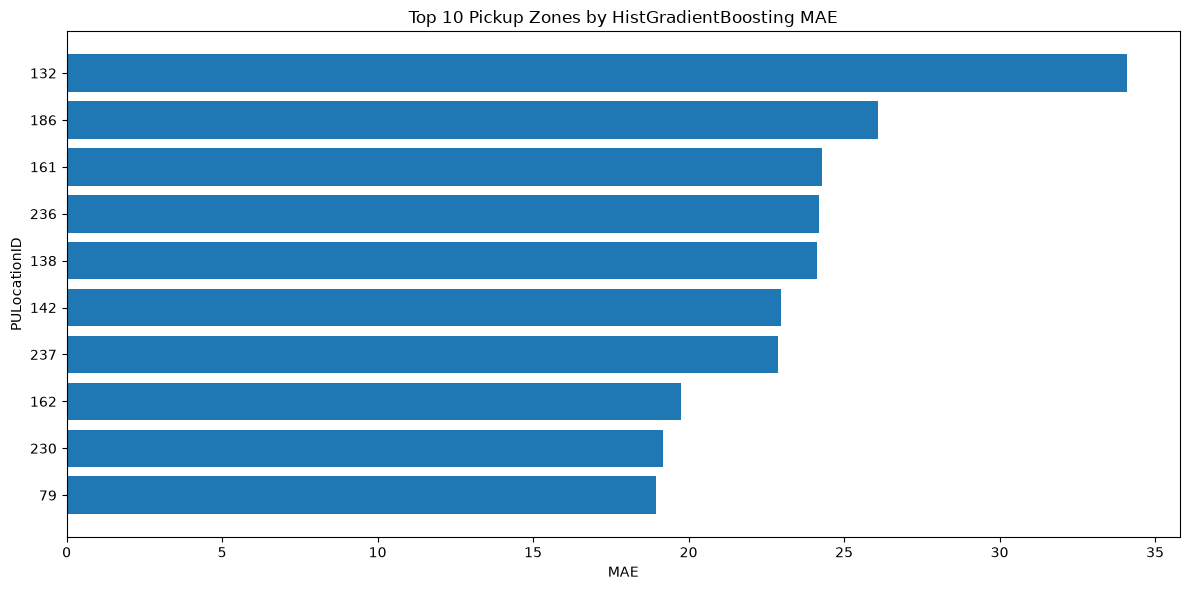

In [12]:
zone_error = (
    error_data.groupby("PULocationID")
    .agg(
        MAE=(best_error_col, "mean"),
        actual_mean=("trip_count", "mean"),
        prediction_mean=("model_3_histgradientboosting_prediction", "mean"),
        observations=("trip_count", "size"),
    )
    .reset_index()
)

zone_error["bias"] = zone_error["prediction_mean"] - zone_error["actual_mean"]
zone_error["relative_MAE"] = zone_error["MAE"] / zone_error["actual_mean"].replace(0, np.nan)

top_10_highest_error_zones = zone_error.sort_values("MAE", ascending=False).head(10)
top_10_lowest_error_zones = zone_error.sort_values("MAE", ascending=True).head(10)

print("Top 10 zones by absolute MAE")
display(top_10_highest_error_zones)

print("Top 10 zones with lowest absolute MAE")
display(top_10_lowest_error_zones)

plt.figure(figsize=(12, 6))
top_plot = top_10_highest_error_zones.sort_values("MAE")
plt.barh(top_plot["PULocationID"].astype(str), top_plot["MAE"])
plt.xlabel("MAE")
plt.ylabel("PULocationID")
plt.title("Top 10 Pickup Zones by HistGradientBoosting MAE")
plt.tight_layout()
plt.show()


## 12. Where does the best model perform poorly?

This section separates **absolute error** from **relative error**. High-demand zones naturally tend to have larger absolute errors, so both views are useful.


In [13]:
high_error = zone_error.copy()

# Keep only zones with nonzero mean actual demand for relative-error ranking.
high_error["relative_MAE_pct"] = high_error["relative_MAE"] * 100

print("Highest absolute MAE zones:")
display(
    high_error.sort_values("MAE", ascending=False)
    .head(15)
    [["PULocationID", "MAE", "actual_mean", "prediction_mean", "bias", "relative_MAE_pct", "observations"]]
)

print("Highest relative MAE zones (nonzero average demand):")
display(
    high_error.dropna(subset=["relative_MAE_pct"])
    .sort_values("relative_MAE_pct", ascending=False)
    .head(15)
    [["PULocationID", "MAE", "actual_mean", "prediction_mean", "bias", "relative_MAE_pct", "observations"]]
)


Highest absolute MAE zones:


,PULocationID,MAE,actual_mean,prediction_mean,bias,relative_MAE_pct,observations
64,132,34.097089,167.139952,167.589679,0.449727,20.400322,836
95,186,26.105488,137.866029,141.644081,3.778052,18.935403,836
84,161,24.305525,191.342105,194.209234,2.867129,12.702654,836
123,236,24.191002,200.607656,206.490066,5.882411,12.058863,836
68,138,24.129146,106.015550,105.386686,-0.628865,22.760007,836
72,142,22.973199,136.226077,140.815027,4.588951,16.864025,836
124,237,22.877711,209.002392,217.801169,8.798777,10.946148,836
85,162,19.755228,141.911483,144.387200,2.475717,13.920810,836
118,230,19.176318,128.594498,131.214921,2.620423,14.912239,836
31,79,18.943518,136.546651,137.817321,1.270670,13.873294,836


Highest relative MAE zones (nonzero average demand):


,PULocationID,MAE,actual_mean,prediction_mean,bias,relative_MAE_pct,observations
48,105,0.007190,0.001196,0.006012,0.004815,601.121076,836
3,8,0.132641,0.061005,0.081337,0.020333,217.426588,836
12,27,0.050016,0.025120,0.026259,0.001139,199.110686,836
132,253,0.061297,0.031100,0.032161,0.001061,197.093634,836
0,2,0.026581,0.014354,0.012513,-0.001841,185.177563,836
24,57,0.186197,0.102871,0.102436,-0.000435,181.000929,836
99,194,0.348242,0.202153,0.247288,0.045135,172.266320,836
14,30,0.065103,0.038278,0.029191,-0.009086,170.081956,836
41,96,0.196338,0.116029,0.105445,-0.010583,169.214845,836
54,120,0.245046,0.147129,0.139800,-0.007329,166.551377,836


## 13. Actual vs predicted demand for the best model


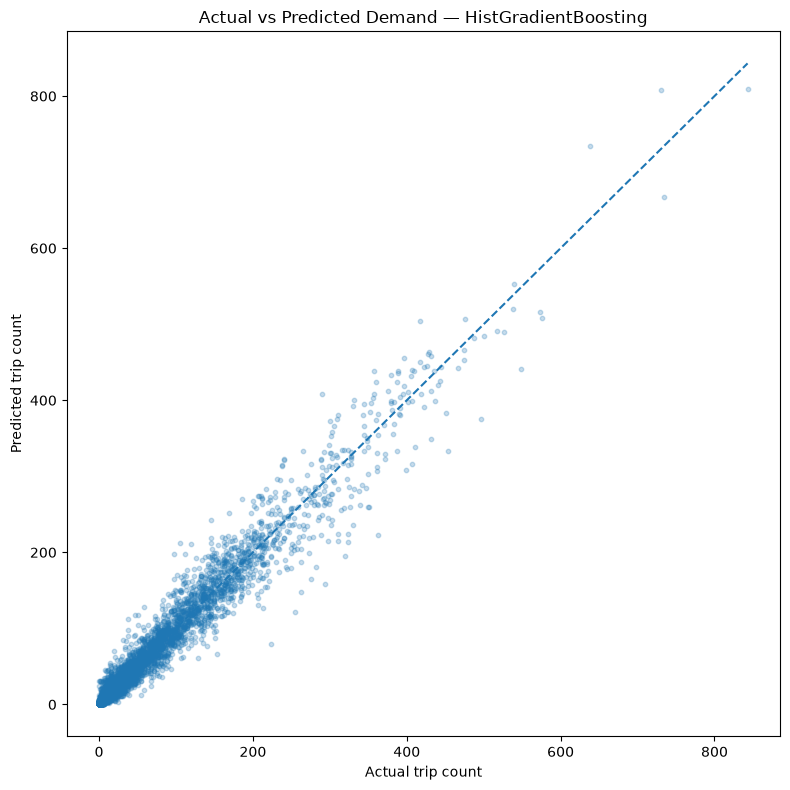

In [14]:
sample_size = min(10000, len(error_data))
plot_sample = error_data.sample(sample_size, random_state=42)

plt.figure(figsize=(8, 8))
plt.scatter(
    plot_sample["trip_count"],
    plot_sample["model_3_histgradientboosting_prediction"],
    alpha=0.25,
    s=10
)

max_value = max(
    plot_sample["trip_count"].max(),
    plot_sample["model_3_histgradientboosting_prediction"].max()
)

plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual trip count")
plt.ylabel("Predicted trip count")
plt.title("Actual vs Predicted Demand — HistGradientBoosting")
plt.tight_layout()
plt.show()


## 14. Residual distribution for the best model


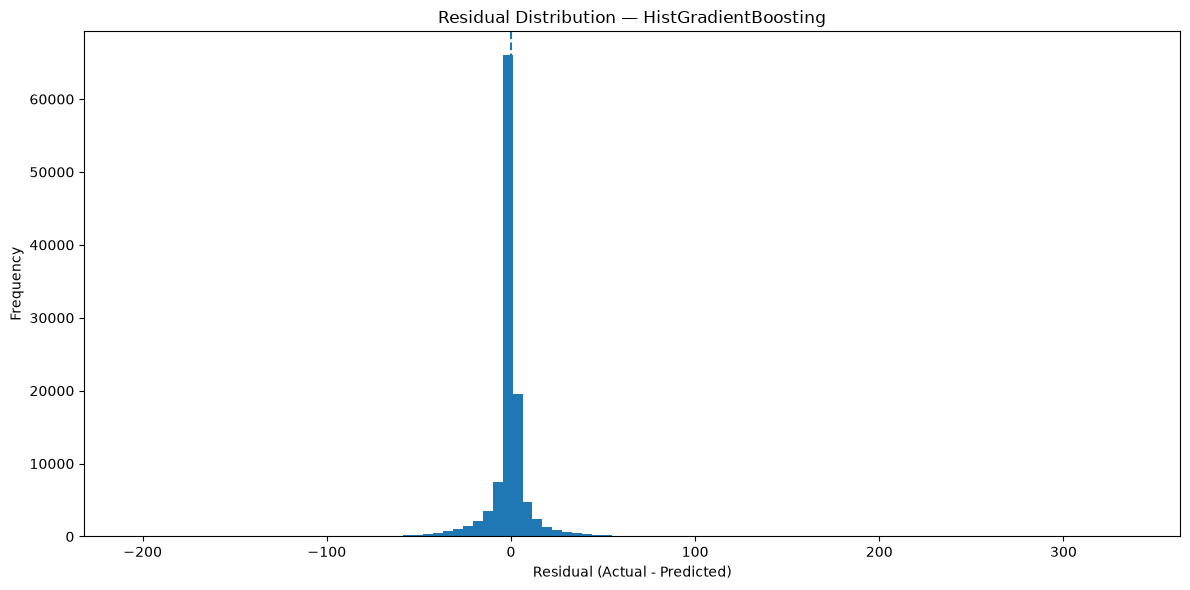

Residual summary:


count    115368.000000
mean         -0.559007
std          13.151364
min        -204.675695
25%          -1.732386
50%          -0.192656
75%           1.139514
max         336.231863
Name: model_3_residual, dtype: float64

In [15]:
error_data["model_3_residual"] = (
    error_data["trip_count"]
    - error_data["model_3_histgradientboosting_prediction"]
)

plt.figure(figsize=(12, 6))
plt.hist(error_data["model_3_residual"], bins=100)
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution — HistGradientBoosting")
plt.tight_layout()
plt.show()

print("Residual summary:")
display(error_data["model_3_residual"].describe())


## 15. Largest individual prediction errors


In [16]:
largest_errors = (
    error_data
    .assign(
        absolute_error=error_data["model_3_histgradientboosting_abs_error"]
    )
    .sort_values("absolute_error", ascending=False)
    .head(20)
)

display(
    largest_errors[
        [
            "PULocationID",
            "pickup_hour",
            "trip_count",
            "model_3_histgradientboosting_prediction",
            "model_3_residual",
            "absolute_error",
        ]
    ]
)


,PULocationID,pickup_hour,trip_count,model_3_histgradientboosting_prediction,model_3_residual,absolute_error
78732,142,2026-02-17 22:00:00,518,181.768137,336.231863,336.231863
88668,142,2026-02-20 22:00:00,601,346.362855,254.637145,254.637145
100666,132,2026-02-24 13:00:00,269,26.606213,242.393787,242.393787
6136,132,2026-01-27 00:00:00,408,170.081933,237.918067,237.918067
72154,230,2026-02-15 22:00:00,427,201.228632,225.771368,225.771368
101494,132,2026-02-24 19:00:00,372,146.569583,225.430417,225.430417
101498,138,2026-02-24 19:00:00,319,93.721141,225.278859,225.278859
25874,138,2026-02-01 23:00:00,319,104.381165,214.618835,214.618835
82044,142,2026-02-18 22:00:00,568,359.083447,208.916553,208.916553
48469,79,2026-02-08 19:00:00,129,333.675695,-204.675695,204.675695


## 16. Save final comparison and error-analysis outputs


In [17]:
comparison_path = MODELING_DIR / "model_comparison_final.csv"
improvement_path = MODELING_DIR / "model_improvement_vs_baseline.csv"
train_test_path = MODELING_DIR / "model_train_test_comparison.csv"
hour_error_path = MODELING_DIR / "model_error_by_hour.csv"
zone_error_path = MODELING_DIR / "model_3_error_by_zone.csv"
largest_error_path = MODELING_DIR / "model_3_largest_errors.csv"

comparison.to_csv(comparison_path, index=False)
improvement.to_csv(improvement_path, index=False)
train_test_wide.to_csv(train_test_path, index=False)
hour_error.to_csv(hour_error_path, index=False)
zone_error.to_csv(zone_error_path, index=False)
largest_errors.to_csv(largest_error_path, index=False)

print("Saved:")
for path in [
    comparison_path,
    improvement_path,
    train_test_path,
    hour_error_path,
    zone_error_path,
    largest_error_path,
]:
    print(" -", path)


Saved:
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/model_comparison_final.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/model_improvement_vs_baseline.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/model_train_test_comparison.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/model_error_by_hour.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/model_3_error_by_zone.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/model_3_largest_errors.csv


# Review 1 — modelling conclusion

After running this notebook, use the outputs to report:

1. Which model performed best on the chronological test set.
2. How much the best model improved over the naive historical baseline.
3. Whether there is evidence of major train/test overfitting.
4. Which hours and pickup zones are hardest to predict.
5. Whether the remaining errors are concentrated in high-demand periods or specific zones.

The **weather contribution experiment should be performed separately** after this comparison, using the same best model with and without weather features.
